# FSRE-AdaTSK: feature selection, rule extraction and fine-tuning

This notebook follows, one step at a time, the classifier of

> G. Xue, Q. Chang, J. Wang, K. Zhang and N. R. Pal, "An adaptive neuro-fuzzy system with
> integrated feature selection and rule extraction for high-dimensional classification
> problems", *IEEE Transactions on Fuzzy Systems*, vol. 31, no. 7, pp. 2167-2181, 2023.

on Wine, one of the datasets of the article. FSRE-AdaTSK trains in three phases: gates
select the features, then gates extract the rules from an enhanced rule base built on the
selected features, and the remaining system is fine-tuned. The notebook is a short
version of the script `examples/reproductions/fsre_adatsk_2022.py`, which runs eight
datasets with ten folds repeated five times; here one repetition on one dataset runs in
a few minutes.

1. settings and reproducibility;
2. the data;
3. the three phases on one fold;
4. why the scale of the inputs matters;
5. what the fitted model looks like;
6. ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import highfis
from highfis import FSREADATSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 1

# The settings of the article: ten fuzzy sets per feature in the feature-selection phase,
# five in the rule-extraction phase, no normalization of the consequent inputs. The number
# of iterations of the rule-extraction phase is not stated; 600 are used.
SETTINGS = dict(fs_n_mfs=10, re_n_mfs=5, re_epochs=600, consequent_batch_norm=False)

# Table IV of the article, Wine: accuracy in percent, selected features, extracted rules.
ARTICLE = (97.3, 6.3, 6.3)

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Wine has 178 samples of three cultivars, described by 13 chemical measurements.

In [3]:
wine = load_wine()
features, labels, feature_names = wine.data.astype(np.float32), wine.target, wine.feature_names

print(f"{features.shape[0]} samples, {features.shape[1]} features, {labels.max() + 1} classes")

178 samples, 13 features, 3 classes


The first of ten folds is followed in detail. The article does not state how the inputs
are scaled; here they are standardized with the mean and the standard deviation of the
training part. Section 4 shows what this choice changes.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))
y_train, y_test = labels[train], labels[test]

scaler = StandardScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 160 samples, test: 18 samples


## 3. The three phases on one fold

1. **Feature selection.** Ten fuzzy sets per feature and ten rules. One gate per feature,
   almost closed at the start, is trained with the system; the features whose gates open
   are kept.
2. **Rule extraction.** Five fuzzy sets on each selected feature, and an enhanced rule
   base of $(2D' + 1) \times 5$ rules for $D'$ selected features. One gate per rule is
   trained; the rules whose gates open are kept.
3. **Fine-tuning** of what remains, without gates.

In [5]:
model = FSREADATSKClassifier(random_state=SEED, **SETTINGS).fit(x_train, y_train)

n_selected = len(model.selected_features_)
print(f"selected features: {n_selected} of {x_train.shape[1]}")
print(f"candidate rules in the rule-extraction phase: {(2 * n_selected + 1) * 5}")
print(f"extracted rules: {model.model_.n_rules}")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")
print([feature_names[d] for d in model.selected_features_])

selected features: 9 of 13
candidate rules in the rule-extraction phase: 95
extracted rules: 5
test accuracy: 100.0%
['alcohol', 'ash', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


The training loss of the three phases. The rule-extraction phase starts again from consequents at zero:

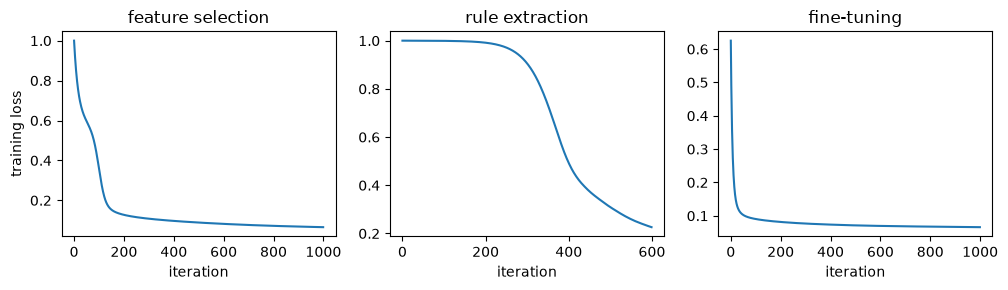

In [6]:
PHASES = {"fs": "feature selection", "re": "rule extraction", "finetune": "fine-tuning"}

fig, axes = plt.subplots(1, len(PHASES), figsize=(3.4 * len(PHASES), 3))
for ax, (key, title) in zip(axes, PHASES.items()):
    ax.plot(model.history_[key]["train_loss"])
    ax.set_title(title)
    ax.set_xlabel("iteration")
axes[0].set_ylabel("training loss")
plt.tight_layout()
plt.show()

The gates of the extracted rules at the end of the rule-extraction phase, and the threshold they passed:

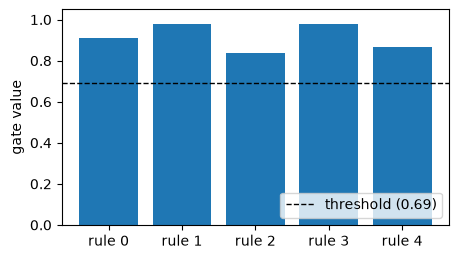

In [7]:
gates = np.abs(np.asarray(model.get_rule_gates()))
threshold = model.history_["tau_theta"]

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(range(len(gates)), gates)
ax.axhline(threshold, color="black", linestyle="--", linewidth=1, label=f"threshold ({threshold:.2f})")
ax.set_xticks(range(len(gates)), [f"rule {rule}" for rule in range(len(gates))])
ax.set_ylabel("gate value")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.show()

## 4. Why the scale of the inputs matters

The membership function of the article is $e^{-(x - m)^2}$, with no spread. The distance
between the centres of two neighbouring fuzzy sets therefore depends on the scale of the
feature. With five sets:

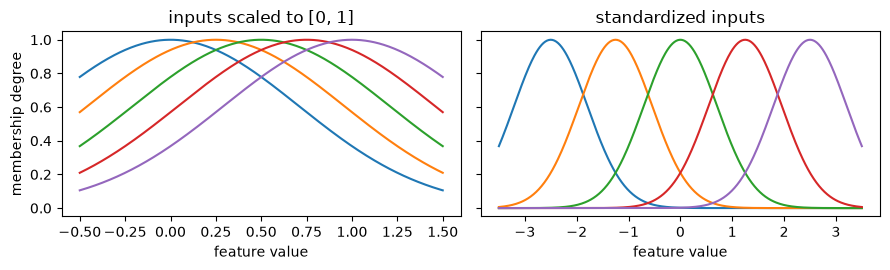

In [8]:
x = np.linspace(-0.5, 1.5, 400)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)

for centre in np.linspace(0, 1, 5):
    axes[0].plot(x, np.exp(-((x - centre) ** 2)))
axes[0].set_title("inputs scaled to [0, 1]")
axes[0].set_xlabel("feature value")
axes[0].set_ylabel("membership degree")

z = np.linspace(-3.5, 3.5, 400)
for centre in np.linspace(-2.5, 2.5, 5):
    axes[1].plot(z, np.exp(-((z - centre) ** 2)))
axes[1].set_title("standardized inputs")
axes[1].set_xlabel("feature value")
plt.tight_layout()
plt.show()

On [0, 1] the five sets almost coincide, the rules of the enhanced rule base fire alike,
and their gates open together: many rules pass the threshold. The same fold with the
inputs scaled to [0, 1]:

In [9]:
unit = MinMaxScaler().fit(features[train])
on_unit = FSREADATSKClassifier(random_state=SEED, **SETTINGS).fit(unit.transform(features[train]), y_train)

print(f"{'inputs':14s} {'features':>9s} {'rules':>6s} {'test accuracy':>14s}")
print(
    f"{'[0, 1]':14s} {len(on_unit.selected_features_):9d} {on_unit.model_.n_rules:6d} "
    f"{100 * on_unit.score(unit.transform(features[test]), y_test):13.1f}%"
)
print(f"{'standardized':14s} {n_selected:9d} {model.model_.n_rules:6d} {100 * model.score(x_test, y_test):13.1f}%")

inputs          features  rules  test accuracy
[0, 1]                 6     20         100.0%
standardized           9      5         100.0%


## 5. What the fitted model looks like

The model on standardized inputs. Its confusion matrix on the 18 test samples, with the
margin of each decision:

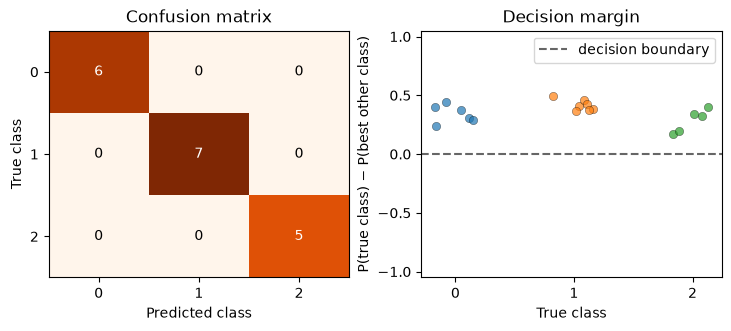

In [10]:
model.plot_diagnostics(x_test, y_test)
plt.show()

How the extracted rules share the samples of each class:

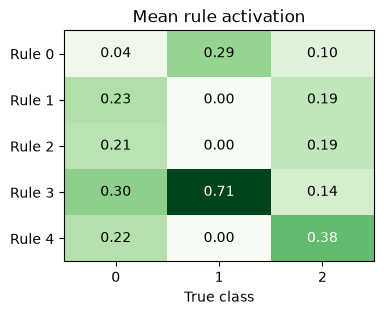

In [11]:
fig, ax = plt.subplots(figsize=(4, 3))
model.plot_rule_activation(x_test, y_test, ax=ax)
plt.show()

The fuzzy sets of four of the selected features, after fine-tuning:

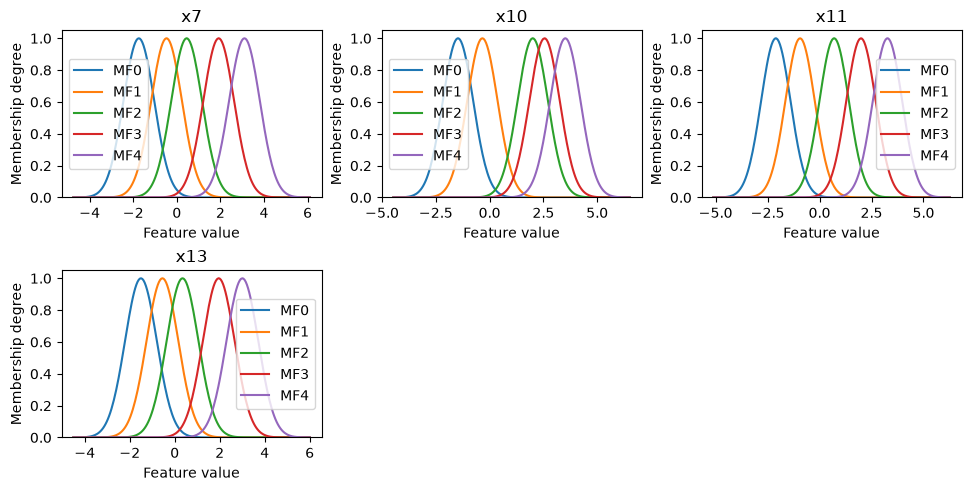

In [12]:
model.plot_memberships(max_features=4)
plt.show()

The rules as sentences, with the three features that weigh most in each consequent:

In [13]:
print(model.rules_as_text(top_features=3))

Rule 0: IF x7 is low AND x10 is low AND x11 is low AND ... (6 more)
        THEN 0: 0.09 + 0.09 * x7 + 0.07 * x13 + 0.03 * x3 + ...
             1: 0.54 - 0.22 * x3 + 0.22 * x11 + 0.17 * x7 + ...
             2: 0.25 - 0.32 * x7 - 0.20 * x11 + 0.19 * x3 + ...
Rule 1: IF x7 is medium AND x10 is medium AND x11 is medium AND ... (6 more)
        THEN 0: 0.41 + 0.22 * x12 + 0.19 * x7 + 0.18 * x3 + ...
             1: 0.12 + 0.16 * x11 - 0.16 * x3 - 0.08 * x1 + ...
             2: 0.29 - 0.24 * x7 + 0.16 * x8 - 0.15 * x11 + ...
Rule 2: IF x7 is medium AND x10 is medium AND x11 is medium AND ... (6 more)
        THEN 0: 0.27 + 0.22 * x1 - 0.21 * x10 + 0.13 * x11 + ...
             1: 0.05 + 0.22 * x7 + 0.16 * x10 - 0.13 * x1 + ...
             2: 0.24 - 0.18 * x11 - 0.15 * x7 + 0.15 * x10 + ...
Rule 3: IF x7 is medium AND x10 is low AND x11 is medium AND ... (6 more)
        THEN 0: 0.58 + 0.31 * x13 + 0.15 * x1 + 0.14 * x10 + ...
             1: 0.44 - 0.29 * x13 - 0.20 * x10 - 0.15 * x1 + 

## 6. Ten folds, next to the article

In [14]:
runs, selections = [], []

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = StandardScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])

    fitted = FSREADATSKClassifier(random_state=SEED, **SETTINGS).fit(a_train, labels[train])
    runs.append((100 * fitted.score(a_test, labels[test]), len(fitted.selected_features_), fitted.model_.n_rules))
    selections.append(fitted.selected_features_)

runs = np.asarray(runs)
print(f"{'':10s} {'accuracy':>9s} {'features':>9s} {'rules':>6s}")
print(f"{'article':10s} {ARTICLE[0]:9.1f} {ARTICLE[1]:9.1f} {ARTICLE[2]:6.1f}")
print(f"{'highFIS':10s} {runs[:, 0].mean():9.1f} {runs[:, 1].mean():9.1f} {runs[:, 2].mean():6.1f}")

            accuracy  features  rules
article         97.3       6.3    6.3
highFIS         95.6       8.1    6.6


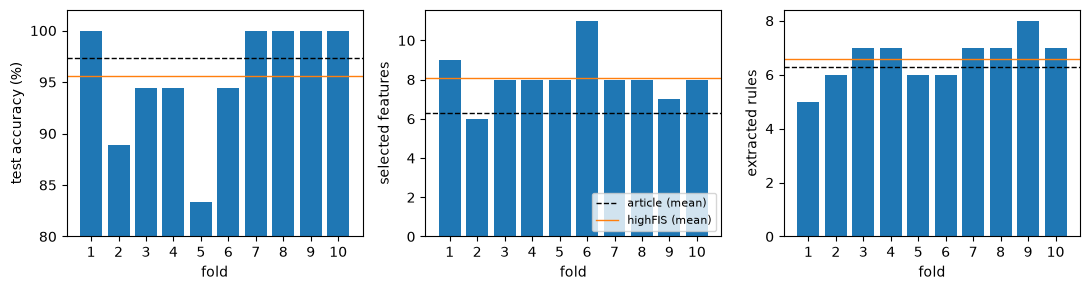

In [15]:
LOWER = 80

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
folds_axis = np.arange(1, FOLDS + 1)
for ax, column, label, reported in zip(axes, range(3), ["test accuracy (%)", "selected features", "extracted rules"], ARTICLE):
    ax.bar(folds_axis, runs[:, column])
    ax.axhline(reported, color="black", linestyle="--", linewidth=1, label="article (mean)")
    ax.axhline(runs[:, column].mean(), color="tab:orange", linewidth=1, label="highFIS (mean)")
    ax.set_xticks(folds_axis)
    ax.set_xlabel("fold")
    ax.set_ylabel(label)
axes[0].set_ylim(LOWER, 102)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

How often each feature is selected over the ten folds:

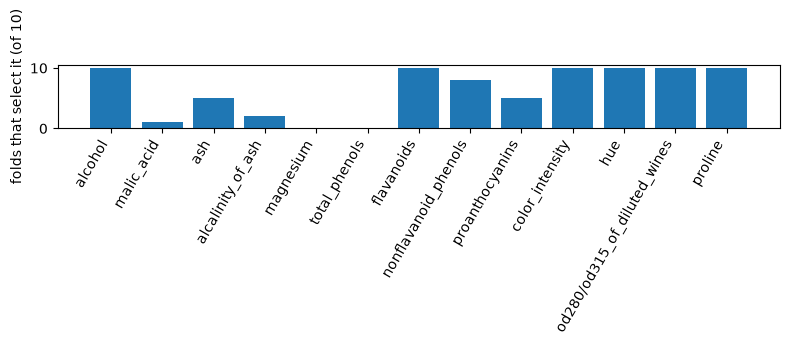

In [16]:
frequency = np.bincount(np.concatenate(selections), minlength=features.shape[1])

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(len(frequency)), frequency)
ax.set_xticks(range(len(frequency)), feature_names, rotation=60, ha="right")
ax.set_ylabel(f"folds that select it (of {FOLDS})")
plt.tight_layout()
plt.show()

The script repeats the ten folds five times, as the article does, and runs seven more
datasets; over the 50 runs Wine gives 96.18% with 8.22 features and 6.80 rules.

## Environment

In [17]:
highfis.show_versions()

highfis       : 0.33.0
python        : 3.11.15
platform      : Linux-7.0.0-38-generic-x86_64-with-glibc2.43
torch         : 2.14.1+cu130
numpy         : 2.4.6
scikit-learn  : 1.9.1
default dtype : torch.float32
threads       : 1
cpu           : Intel(R) Core(TM) Ultra 7 258V
